<h1><center>Eksploracja danych - Laboratorium 6</center></h1>
<h2><center>Faktoryzacja Macierzy Nieujemnych</center></h2>
<p><center>Wojciech Olejnik</center></p>


**Celem laboratorium jest zapoznanie się z Faktoryzacja Macierzy Nieujem-nych i użycie jej do ekstrakcji cech z obrazów.**

**Zadanie 1. Zaimplementowqać algorytm nieujemnej faktoryzacji macierzy (NMF)**

In [1]:
from sklearn.decomposition import NMF
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from numpy.random import RandomState # Create a random seed
import copy
import numpy as np
from sklearn import datasets
from sklearn.decomposition import PCA

In [23]:
class MyNMF(object):
    def __init__(self, n_c = 2, N = 5000, ep = 0.0001):
        self.W = None
        self.V = None
        self.H = None
        self.n_components = n_c
        self.N = N
        self.ep = ep
        
    def calc_V(self, X):
        self.W = X[:,0:self.n_components]
        self.V = copy.deepcopy(X)
        self.H = np.random.rand(self.n_components, X.shape[1])
        ep_H = np.ones(self.H.shape) * self.ep
        ep_W = np.ones(self.W.shape) * self.ep
        
        for it in range(0, self.N):
            #udapte step by step
            tmp_H = self.H * ((np.dot(self.W.T, self.V)) / (np.dot(np.dot(self.W.T, self.W), self.H)))
            tmp_W = self.W * ((np.dot(self.V, tmp_H.T)) / (np.dot(np.dot(self.W, tmp_H), tmp_H.T)))
            self.H = abs(self.H - tmp_H) <= ep_H
            self.W = abs(self.W - tmp_W) <= ep_W
            
#             if compare_H.all() and compare_W.all():
#                 self.H = copy.deepcopy(tmp_H)
#                 self.W = copy.deepcopy(tmp_W)
#                 break
            self.H = copy.copy(tmp_H)
            self.W = copy.copy(tmp_W)              
#             self.H = copy.deepcopy(tmp_H)
#             self.W = copy.deepcopy(tmp_W)
            
        self.components = self.H
        return self.W


Wczytanie danych **iris**

In [24]:
iris = datasets.load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

**Wykres dla PCA**

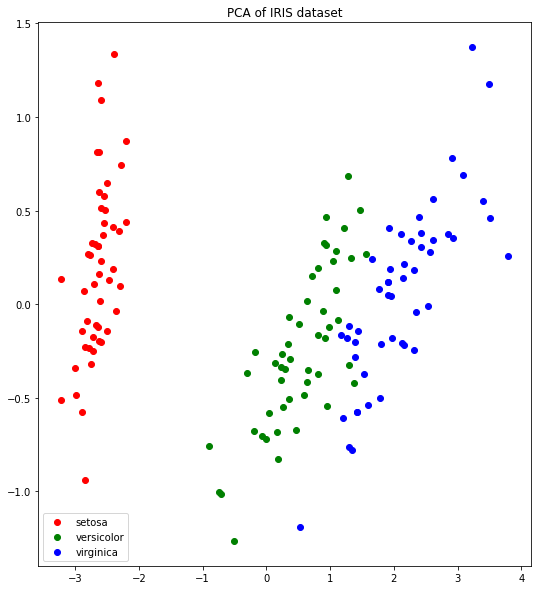

In [25]:
f = plt.figure(figsize=(30,10))
pca_chart = f.add_subplot(133)
pca = PCA(n_components=2)
X_r = pca.fit(X).transform(X)
for c, i, target_name in zip("rgb", [0, 1, 2], target_names):
    pca_chart.scatter(X_r[y==i,0], X_r[y==i,1], c=c, label=target_name)
pca_chart.legend()
plt.title('PCA of IRIS dataset')
plt.show()

Text(0.5, 1.0, 'NMF of IRIS dataset')

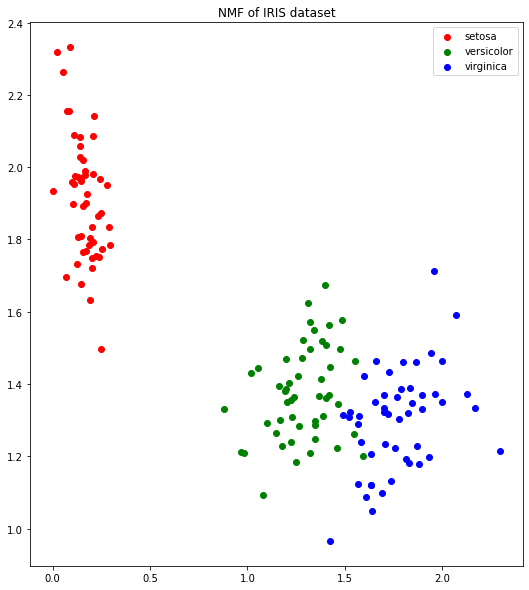

In [26]:
f = plt.figure(figsize=(30,10))
nmf = NMF(n_components=2, init='random', random_state=0, max_iter=1000)
W = nmf.fit_transform(X)
H = nmf.components_
nmf_chart = f.add_subplot(132)
for c, i, target_name in zip("rgb", [0, 1, 2], target_names):
    nmf_chart.scatter(W[y==i,0], W[y==i,1], c=c, label=target_name)
nmf_chart.legend()
plt.title('NMF of IRIS dataset')

Text(0.5, 1.0, 'My NMF of IRIS dataset')

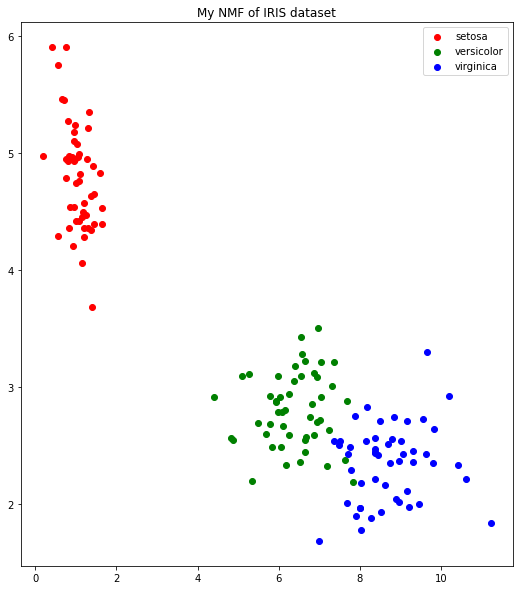

In [27]:
my_NMF = MyNMF()
W = my_NMF.calc_V(X=X)
H = my_NMF.components
f = plt.figure(figsize=(30,10))
ax = f.add_subplot(131)
for c, i, target_name in zip("rgb", [0, 1, 2], target_names):
    ax.scatter(W[y==i,0], W[y==i,1], c=c, label=target_name)
ax.legend()
plt.title('My NMF of IRIS dataset')